# 04 Evaluation homework

Imports

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

%matplotlib inline

Data preparation

In [89]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [90]:
display(df.dtypes, df.isnull().sum())

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [91]:
categorical = df.columns[df.dtypes == "str"].to_list()
numerical = df.columns.difference(categorical + ["converted"], sort=False).to_list()

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [92]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [93]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train["converted"]
del df_val["converted"]
del df_test["converted"]

## Question 1

In [94]:
scores_dict = {}

for n in numerical:
    auc = roc_auc_score(y_train, df_train[n])
    
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[n])
        
    scores_dict[n] = auc
    
scores_dict = dict(sorted(scores_dict.items(), key=lambda x: x[1], reverse=True))
    
for i, (k, v) in enumerate(scores_dict.items(), 1):
    display(f"{i}. {k} - {v}")

'1. lead_score - 0.7882254810906102'

'2. interaction_count - 0.7649203047563227'

'3. number_of_courses_viewed - 0.7229894623989618'

'4. annual_income - 0.6081977776250831'

Answer: lead_score

## Question 2

In [95]:
df_train_dicts = df_train[categorical + numerical].to_dict(orient="records")
df_val_dicts = df_val[categorical + numerical].to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train_dicts)
X_val = dv.transform(df_val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
np.round(roc_auc_score(y_val, y_pred), 3)

np.float64(0.732)

Answer: 0.732

## Question 3

In [96]:
thresholds = np.linspace(0, 1, 101)
precisions, recalls = [], []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    precisions.append(tp / (tp + fp))
    recalls.append(tp / (tp + fn))

C:\Users\crtdo\AppData\Local\Temp\ipykernel_15948\1367795259.py:17: RuntimeWarning: invalid value encountered in scalar divide
  precisions.append(tp / (tp + fp))


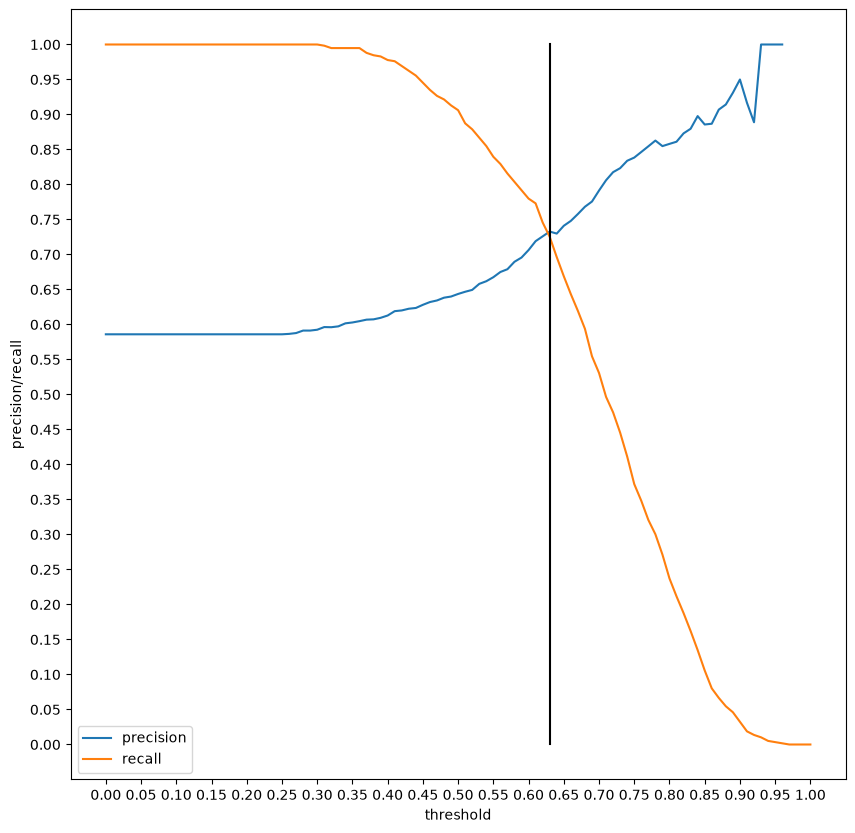

In [97]:
plt.figure(figsize=(10, 10))

plt.plot(thresholds, precisions, label="precision")
plt.plot(thresholds, recalls, label="recall")

plt.plot(np.ones(len(thresholds)) * 0.63, thresholds, color="black")

plt.xlabel("threshold")
plt.ylabel("precision/recall")
plt.xticks(np.linspace(0, 1, 21))
plt.yticks(np.linspace(0, 1, 21))

plt.legend()

Answer: 0.63

## Question 4

In [98]:
thresholds = np.linspace(0, 1, 101)
precisions, recalls = [], []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    precisions.append(tp / (tp + fp))
    recalls.append(tp / (tp + fn))

C:\Users\crtdo\AppData\Local\Temp\ipykernel_15948\1367795259.py:17: RuntimeWarning: invalid value encountered in scalar divide
  precisions.append(tp / (tp + fp))


In [99]:
precisions_np = np.array(precisions)
recalls_np = np.array(recalls)

f1 = 2 * (precisions_np * recalls_np) / (precisions_np + recalls_np)
f1_tuples = sorted(zip(thresholds, f1), key=lambda x: x[1], reverse=True)

for i, (t, f) in enumerate(f1_tuples[:5], 1):
    display(f"{i}. {t}: {f}")

'1. 0.41000000000000003: 0.7576158940397352'

'2. 0.42: 0.7563249001331558'

'3. 0.43: 0.7560321715817694'

'4. 0.45: 0.7547683923705722'

'5. 0.44: 0.7547169811320755'

Answer: 0.41

## Question 5

In [100]:
def train(df, y_train, C=1.0):
    dicts = df[categorical + numerical].to_dict(orient="records")
    
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model
    

In [101]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient="records")
    
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    
    return y_pred

In [102]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)
    
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
    
np.std(scores).round(3)

np.float64(0.007)

Answer: 0.007

## Question 6

In [103]:
reg_tuples = []

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        
        y_train = df_train.converted.values
        y_val = df_val.converted.values
        
        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
        
    reg_tuples.append(
        (
            C, np.std(scores).round(3), np.mean(scores).round(3)
        )
    )

In [104]:
reg_tuples.sort(key=lambda x: x[2], reverse=True)
for i, (C, std, mean) in enumerate(reg_tuples, 1):
    display(f"{i}. C = {C}: std = {std}, mean = {mean}")

'1. C = 0.001: std = 0.01, mean = 0.749'

'2. C = 1: std = 0.007, mean = 0.732'

'3. C = 1e-06: std = 0.019, mean = 0.617'

Answer: 0.001